# Tuning model Minggu 10 - DATA SINTETIS / SIMULASI

Eksperimen terpisah dari model serving. Target tetap `future_7d_mean_sbp`.
Persetujuan target diasumsikan untuk tugas ini; artefak aktif tidak diubah.

**Protokol:** grid terbatas RF/HGB + LR pembanding; 4-fold GroupKFold di train;
preprocessing per fold; pemilihan RMSE OOF lalu MAE; evaluasi test historis setelah pemilihan.

**Batas:** inner CV memisahkan ID tetapi tidak waktu. Kalender train terlalu singkat
untuk purged temporal CV. Test lama pernah diperiksa; bukan evaluasi holdout baru.
Menjalankan notebook menulis hanya artefak tuning terpisah dan laporan/figurnya.
Tidak mengakses database atau melatih dari data aktual.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'backend').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'backend/app/model_tuning.py').is_file(), 'Jalankan dari root atau notebooks/'
sys.path.insert(0, str(ROOT))
from etl.run_week10_tuning import execute
result = execute()

Run e34327cd28c78f592900 | 17 kandidat | terpilih Linear Regression
Artefak aktif tidak berubah; tidak ada promosi model. DATA SINTETIS / SIMULASI.


In [2]:
import pandas as pd
trials = pd.read_csv(ROOT / 'reports/week10_tuning/validation_trials.csv')
display(trials.sort_values(['model', 'rmse', 'mae']))
display(pd.read_csv(ROOT / 'reports/week10_tuning/comparison.csv'))
print('Terpilih hanya dari validasi:', result['selection'])
print(result['limitation'])

,model,params,original,mae,rmse,r2,n
11,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.317747,4.510413,0.512413,60
15,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",True,3.352950,4.599921,0.492869,60
13,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.338598,4.610573,0.490518,60
9,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.371457,4.730849,0.463589,60
12,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.378044,4.776791,0.453121,60
14,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.349091,4.815344,0.444257,60
10,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.454139,4.896086,0.425464,60
16,Hist Gradient Boosting,"{""l2_regularization"": 1.0, ""learning_rate"": 0....",False,3.596992,4.925122,0.418629,60
0,Linear Regression,{},True,2.180456,2.758826,0.817582,60
3,Random Forest,"{""max_depth"": 2, ""max_features"": 1.0, ""min_sam...",False,2.911711,4.324732,0.551732,60


,model,stage,split,mae,rmse,r2,n
0,Naive 7-day mean,reference,validation,1.907738,2.376512,0.864637,60
1,Naive 7-day mean,reference,historical_test,1.933673,2.234723,0.850309,7
2,Linear Regression,original,validation,2.180456,2.758826,0.817582,60
3,Linear Regression,original,historical_test,2.575492,3.113985,0.709343,7
4,Linear Regression,selected_configuration,validation,2.180456,2.758826,0.817582,60
5,Linear Regression,selected_configuration,historical_test,2.575492,3.113985,0.709343,7
6,Random Forest,original,validation,3.177825,4.750046,0.459227,60
7,Random Forest,original,historical_test,2.959332,3.440747,0.645143,7
8,Random Forest,selected_configuration,validation,2.911711,4.324732,0.551732,60
9,Random Forest,selected_configuration,historical_test,2.682003,3.236340,0.686053,7


Terpilih hanya dari validasi: {'model': 'Linear Regression', 'params': {}, 'rule': 'minimum pooled out-of-fold RMSE, then MAE, then canonical candidate key; learned models only', 'beats_naive_validation': False}
DATA SINTETIS / SIMULASI. Inner GroupKFold memisahkan ID, tetapi kalender fit/validasi dapat beririsan dan target window training berkorelasi. Ini bukan validasi forecasting kronologis penuh. Test CP3 sudah pernah diperiksa; evaluasi ulang bersifat historis, bukan holdout baru. Sampel kecil; bukan validasi klinis atau hasil data aktual. Persetujuan target diasumsikan untuk tugas ini; bukti akademik belum direkam dalam artefak aktif.


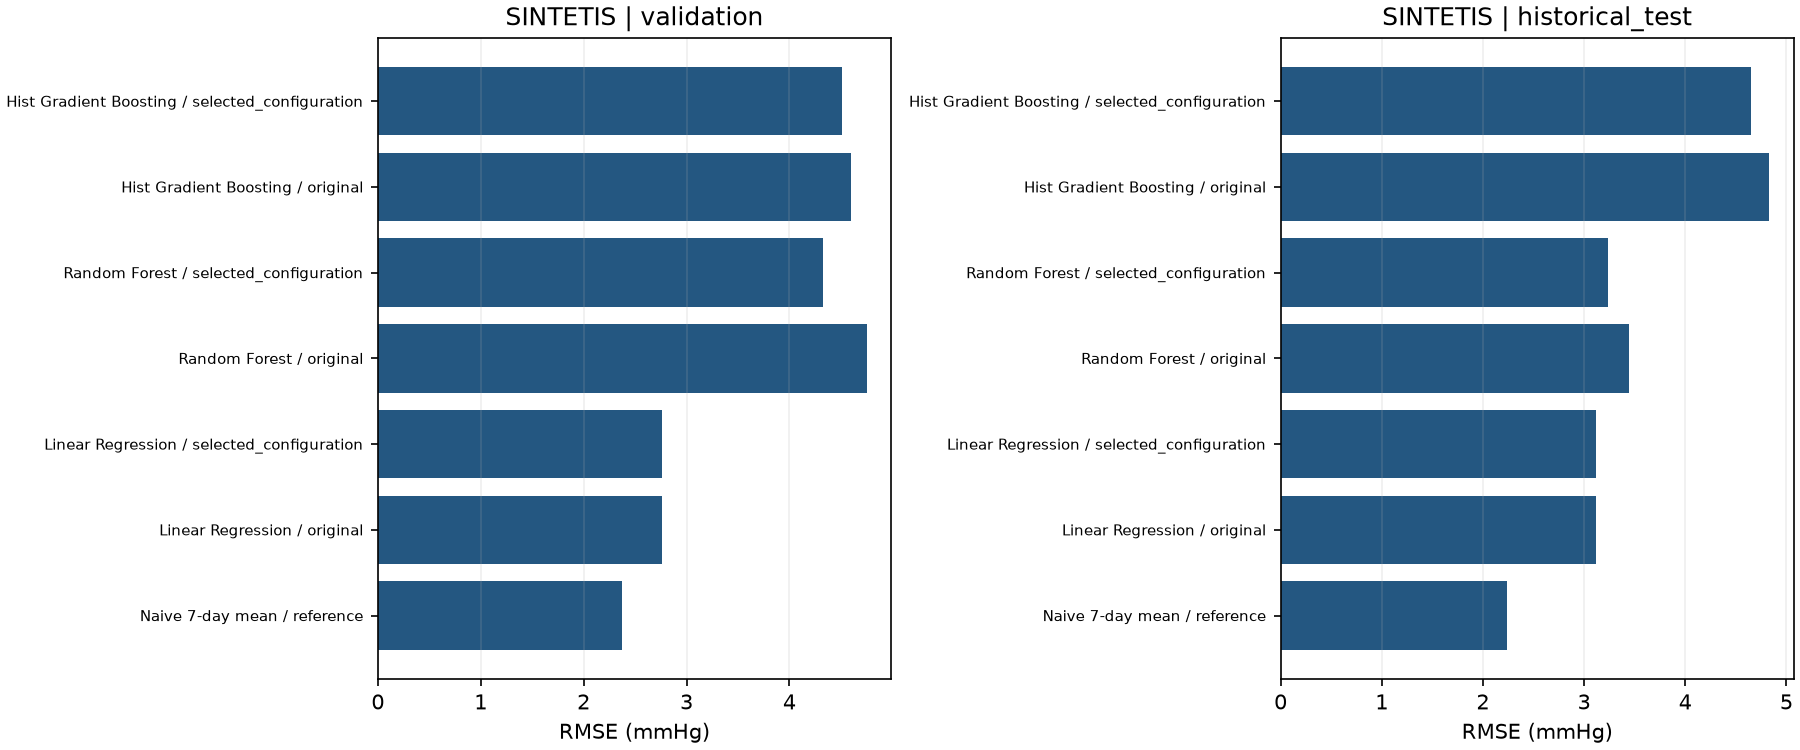

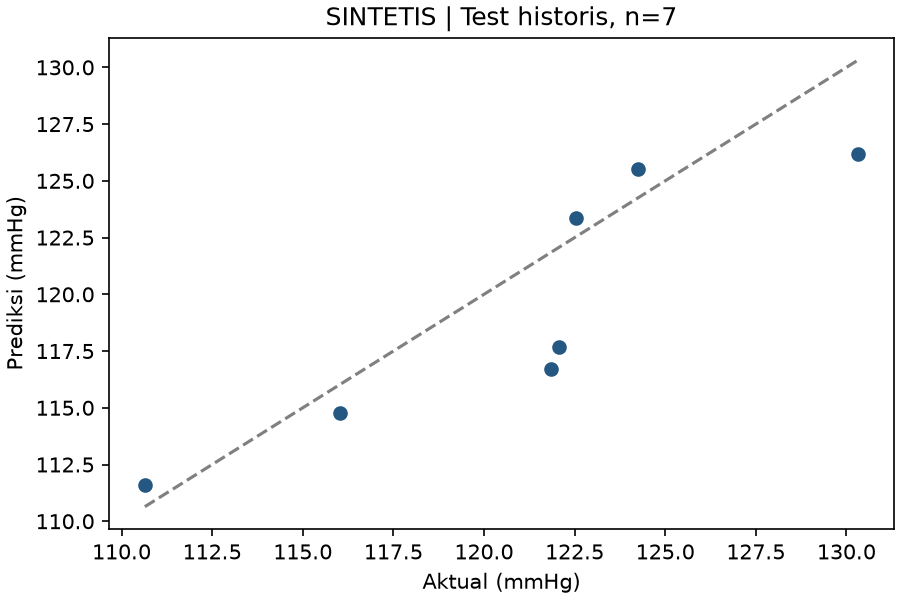

In [3]:
from IPython.display import Image, display
for name in ['rmse_before_after.png', 'historical_actual_prediction.png']:
    display(Image(filename=str(ROOT / 'reports/week10_tuning/figures' / name)))

## Interpretasi
Bandingkan perubahan skor original ke selected_configuration pada setiap algoritma.
Pilihan model terlatih tidak berarti mengalahkan baseline naif; periksa flag hasil.
Tidak menyebut skor test historis sebagai performa baru yang tidak bias.
Baca `docs/WEEK10_TUNING_REPORT.md` untuk keputusan, batas dan reproduksi.
Promosi model, validasi aktual, dan integrasi dashboard berada di luar langkah ini.